## Import libraries and load data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import numpy as np
import seaborn as sns
from collections import Counter, defaultdict
import warnings
warnings.filterwarnings('ignore')
 

In [ ]:
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 150,
})
 
EXCEL_PATH = "Included_Studies_Taxonomy_FINAL.xlsx"

def load_data(path=EXCEL_PATH):
    df = pd.read_excel(path, sheet_name="Analysis Set", header=0)
    df = df[df['in_final_analysis'].str.strip().str.lower() == 'yes'].copy()
    # Clean string columns
    for col in df.select_dtypes(include='object').columns:
        df[col] = df[col].astype(str).str.strip().replace('None', pd.NA).replace('nan', pd.NA)
    return df


df = load_data()
print(f"Loaded: {len(df)} activity rows across {df['paper_id'].nunique()} papers")
print(f"Activity codes: {df['final_code'].nunique()}")
print(f"Years: {sorted(df['year'].dropna().unique())}")

### Figure 2: Activity frequency × Division of work

##### a

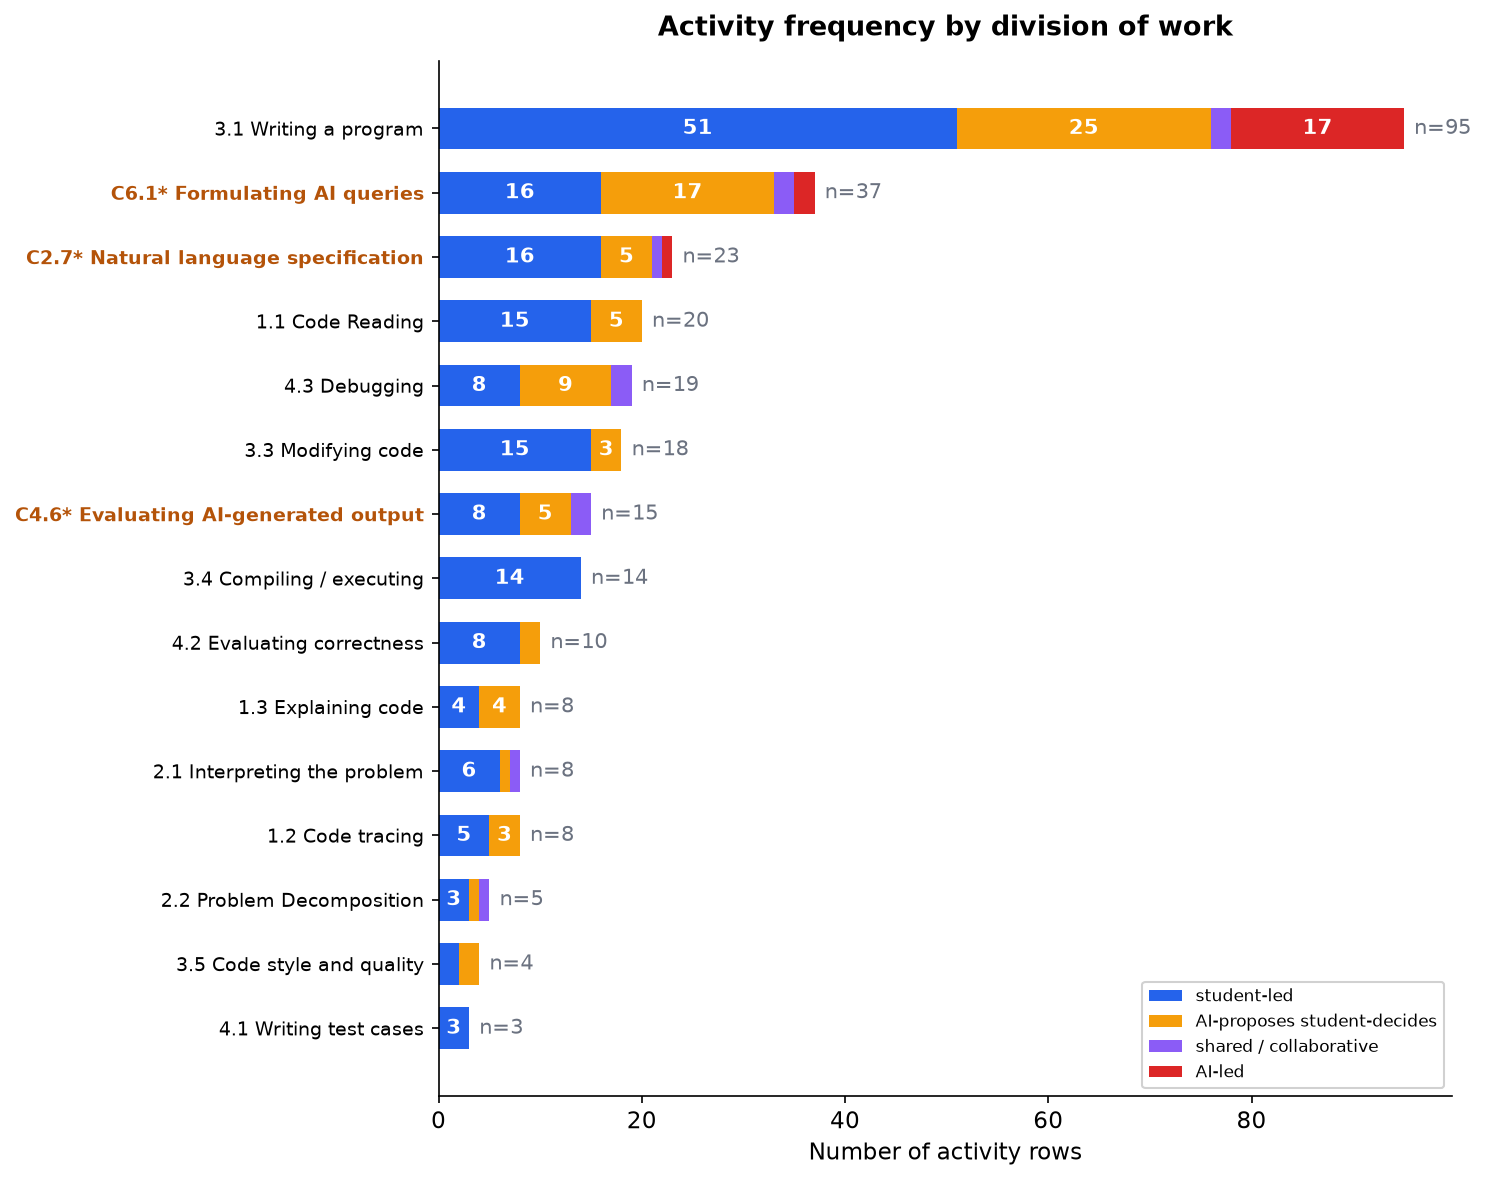

In [ ]:
def fig_rq1_activity_division(df):
    div_colors = {
        'student-led': '#2563eb',
        'AI-proposes student-decides': '#f59e0b',
        'shared / collaborative': '#8b5cf6',
        'AI-led': '#dc2626',
    }
    div_order = list(div_colors.keys())
 
    df = df.copy()
    df['act_label'] = df['final_code'] + ' ' + df['final_label']
 
    ct = df.groupby(['act_label', 'division_of_work']).size().unstack(fill_value=0)
    ct = ct.reindex(columns=[c for c in div_order if c in ct.columns], fill_value=0)
    ct['_total'] = ct.sum(axis=1)
    ct = ct[ct['_total'] >= 3].sort_values('_total', ascending=True)
    totals = ct['_total'].copy()
    ct = ct.drop(columns=['_total'])
 
    fig, ax = plt.subplots(figsize=(10, 8))
    left = np.zeros(len(ct))
    for col in ct.columns:
        color = div_colors.get(col, '#9ca3af')
        

        ct = ct.rename(index={'NEW-P Prompting / NL specification': 'C2.7* Natural language specification',
                            'NEW-Q Querying AI for help': 'C6.1* Formulating AI queries',
                            'NEW-E Evaluating AI output': 'C4.6* Evaluating AI-generated output'})

        bars = ax.barh(ct.index, ct[col], left=left, color=color, label=col, height=0.65)
        for bar, val in zip(bars, ct[col]):
            if val >= 3:
                ax.text(bar.get_x() + bar.get_width()/2, bar.get_y() + bar.get_height()/2,
                        str(int(val)), ha='center', va='center', fontsize=10, color='white', fontweight='bold')
        left += ct[col].values
 
    for i, (idx, total) in enumerate(totals.items()):
        ax.text(total + 1, i, f'n={int(total)}', va='center', fontsize=10, color='#6b7280')
 
    for i, label in enumerate(ct.index):
        if '*' in label:
            ax.get_yticklabels()[i].set_color('#b45309')
            ax.get_yticklabels()[i].set_fontweight('bold')
 
    ax.set_xlabel('Number of activity rows')
    ax.set_title('Activity frequency by division of work', fontweight='bold', pad=12)
    ax.legend(loc='lower right', fontsize=8, framealpha=0.9)
    ax.tick_params(axis='y', labelsize=9)
    plt.tight_layout()
    # plt.savefig('fig/fig_rq1_activity_division.png', dpi=300, bbox_inches='tight')
    plt.show()
 
fig_rq1_activity_division(df)

##### b

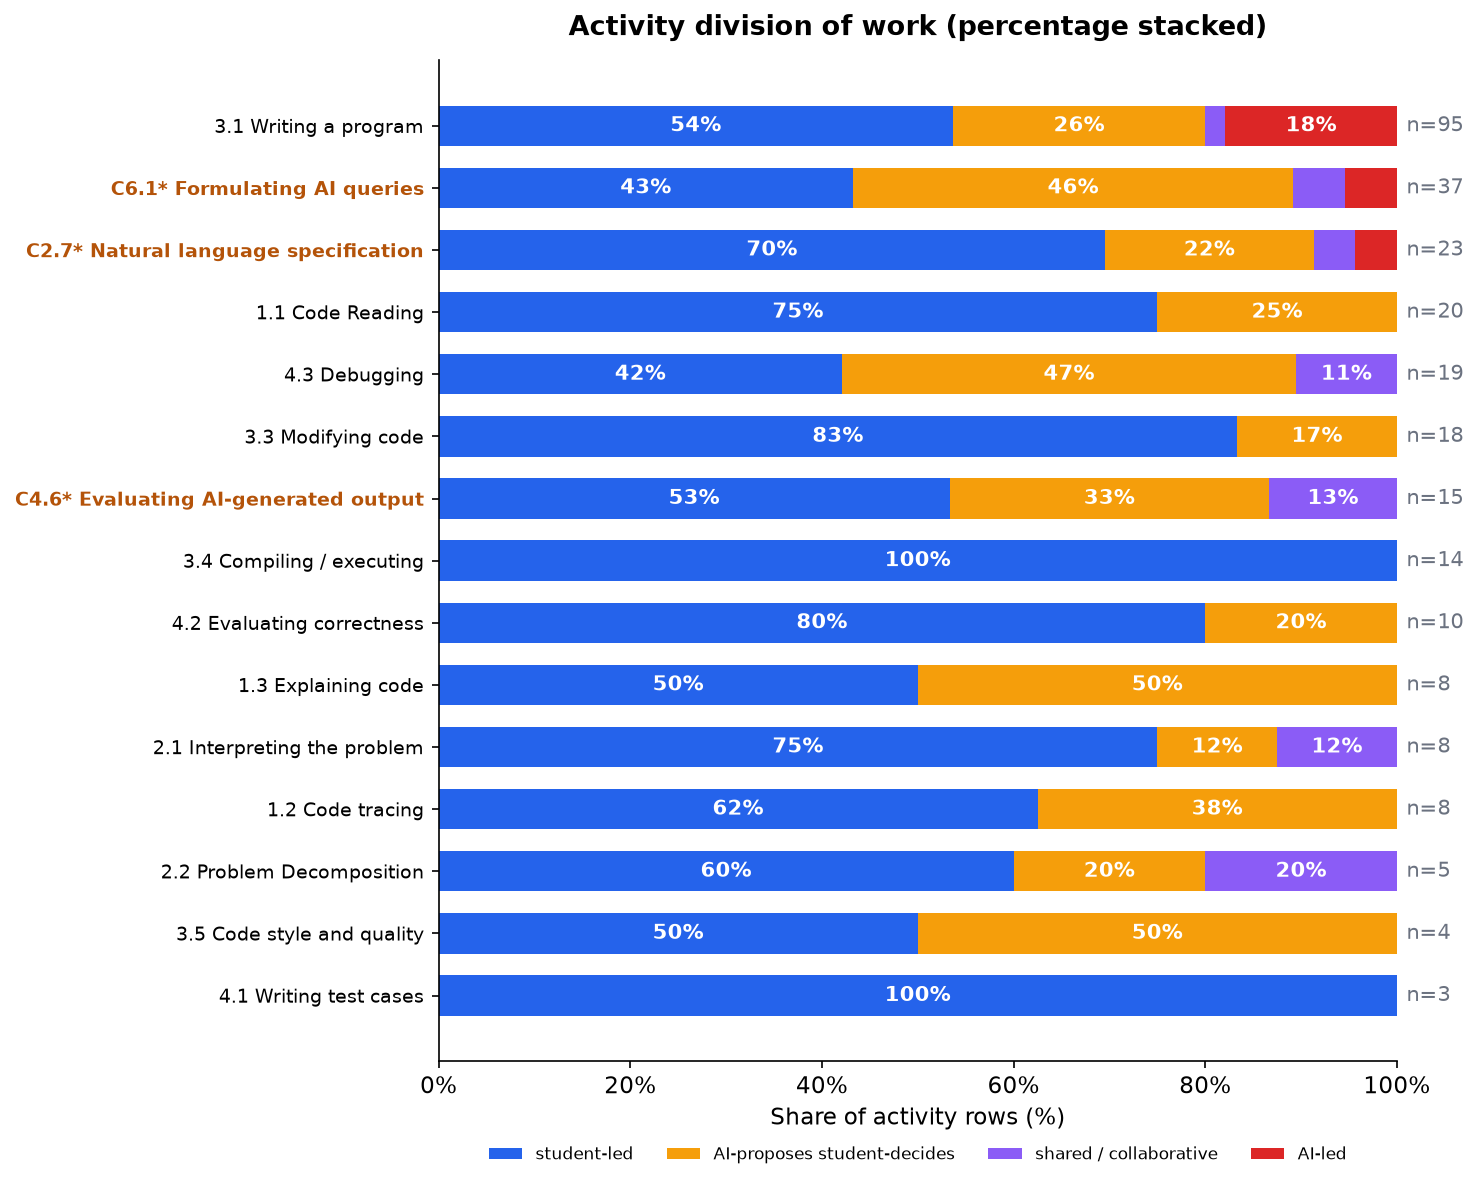

In [ ]:
def fig_rq1_activity_division_pct(df):
    div_colors = {
        'student-led': '#2563eb',
        'AI-proposes student-decides': '#f59e0b',
        'shared / collaborative': '#8b5cf6',
        'AI-led': '#dc2626',
    }
    div_order = list(div_colors.keys())

    df = df.copy()
    df['act_label'] = df['final_code'] + ' ' + df['final_label']

    ct = df.groupby(['act_label', 'division_of_work']).size().unstack(fill_value=0)
    ct = ct.reindex(columns=[c for c in div_order if c in ct.columns], fill_value=0)
    ct['_total'] = ct.sum(axis=1)
    ct = ct[ct['_total'] >= 3].sort_values('_total', ascending=True)  # same rows/order as Figure 1
    totals = ct['_total'].copy()
    ct = ct.drop(columns=['_total'])
    pct = ct.div(totals, axis=0) * 100

    fig, ax = plt.subplots(figsize=(10, 8))
    left = np.zeros(len(pct))
    for col in pct.columns:
        color = div_colors.get(col, '#9ca3af')
        pct = pct.rename(index={'NEW-P Prompting / NL specification': 'C2.7* Natural language specification',
                                    'NEW-Q Querying AI for help': 'C6.1* Formulating AI queries',
                                    'NEW-E Evaluating AI output': 'C4.6* Evaluating AI-generated output'})
        
        bars = ax.barh(pct.index, pct[col], left=left, color=color, label=col, height=0.65)
        for bar, p, n in zip(bars, pct[col], ct[col]):
            if p >= 7:
                ax.text(bar.get_x() + bar.get_width()/2, bar.get_y() + bar.get_height()/2,
                        f'{p:.0f}%', ha='center', va='center', fontsize=10, color='white', fontweight='bold')
        left += pct[col].values

    ax.set_xlim(0, 100)
    ax.set_xticks(range(0, 101, 20))
    ax.set_xticklabels([f'{t}%' for t in range(0, 101, 20)])

    # n per activity, right of the 100% bar
    for i, total in enumerate(totals.values):
        ax.text(101, i, f'n={int(total)}', va='center', fontsize=10, color='#6b7280')

    for i, label in enumerate(pct.index):
        if '*' in label:
            ax.get_yticklabels()[i].set_color('#b45309')
            ax.get_yticklabels()[i].set_fontweight('bold')

    ax.set_xlabel('Share of activity rows (%)')
    ax.set_title('Activity division of work (percentage stacked)', fontweight='bold', pad=12)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.07), ncol=4, fontsize=8, frameon=False)
    ax.tick_params(axis='y', labelsize=9)
    plt.tight_layout()
    plt.savefig('fig/fig_rq1_activity_division_pct.png', dpi=300, bbox_inches='tight')
    plt.show()

fig_rq1_activity_division_pct(df)


### Recode Data

In [15]:
def load_and_recode(path=EXCEL_PATH):
    df = pd.read_excel(path, sheet_name="Analysis Set", header=0)
    df = df[df['in_final_analysis'].str.strip().str.lower() == 'yes'].copy()
    for col in df.select_dtypes(include='object').columns:
        df[col] = df[col].astype(str).str.strip().replace('None', pd.NA).replace('nan', pd.NA)
 
    # Derive implementation coding from division_of_work
    def recode(div):
        if div == 'student-led':
            return 'Student-implemented'
        elif div == 'AI-proposes student-decides':
            return 'AI-implemented'
        elif div == 'AI-led':
            return 'AI-implemented'
        elif div == 'shared / collaborative':
            return 'Shared'
        else:
            return 'Other'
 
    def subcode(div):
        if div == 'AI-proposes student-decides':
            return 'With student evaluation'
        elif div == 'AI-led':
            return 'Without student evaluation'
        else:
            return None
 
    df['implementation'] = df['division_of_work'].apply(recode)
    df['ai_subcode'] = df['division_of_work'].apply(subcode)
    return df
 
df = load_and_recode()
print(f"Loaded: {len(df)} rows, {df['paper_id'].nunique()} papers")
print(f"\nImplementation coding:")
print(df['implementation'].value_counts().to_string())
print(f"\nAI sub-codes:")
print(df['ai_subcode'].value_counts(dropna=False).to_string())

Loaded: 294 rows, 110 papers

Implementation coding:
implementation
Student-implemented    177
AI-implemented         106
Shared                  11

AI sub-codes:
ai_subcode
None                          188
With student evaluation        86
Without student evaluation     20


### Figure 3: Activity × Implementation (student vs AI binary)


##### a

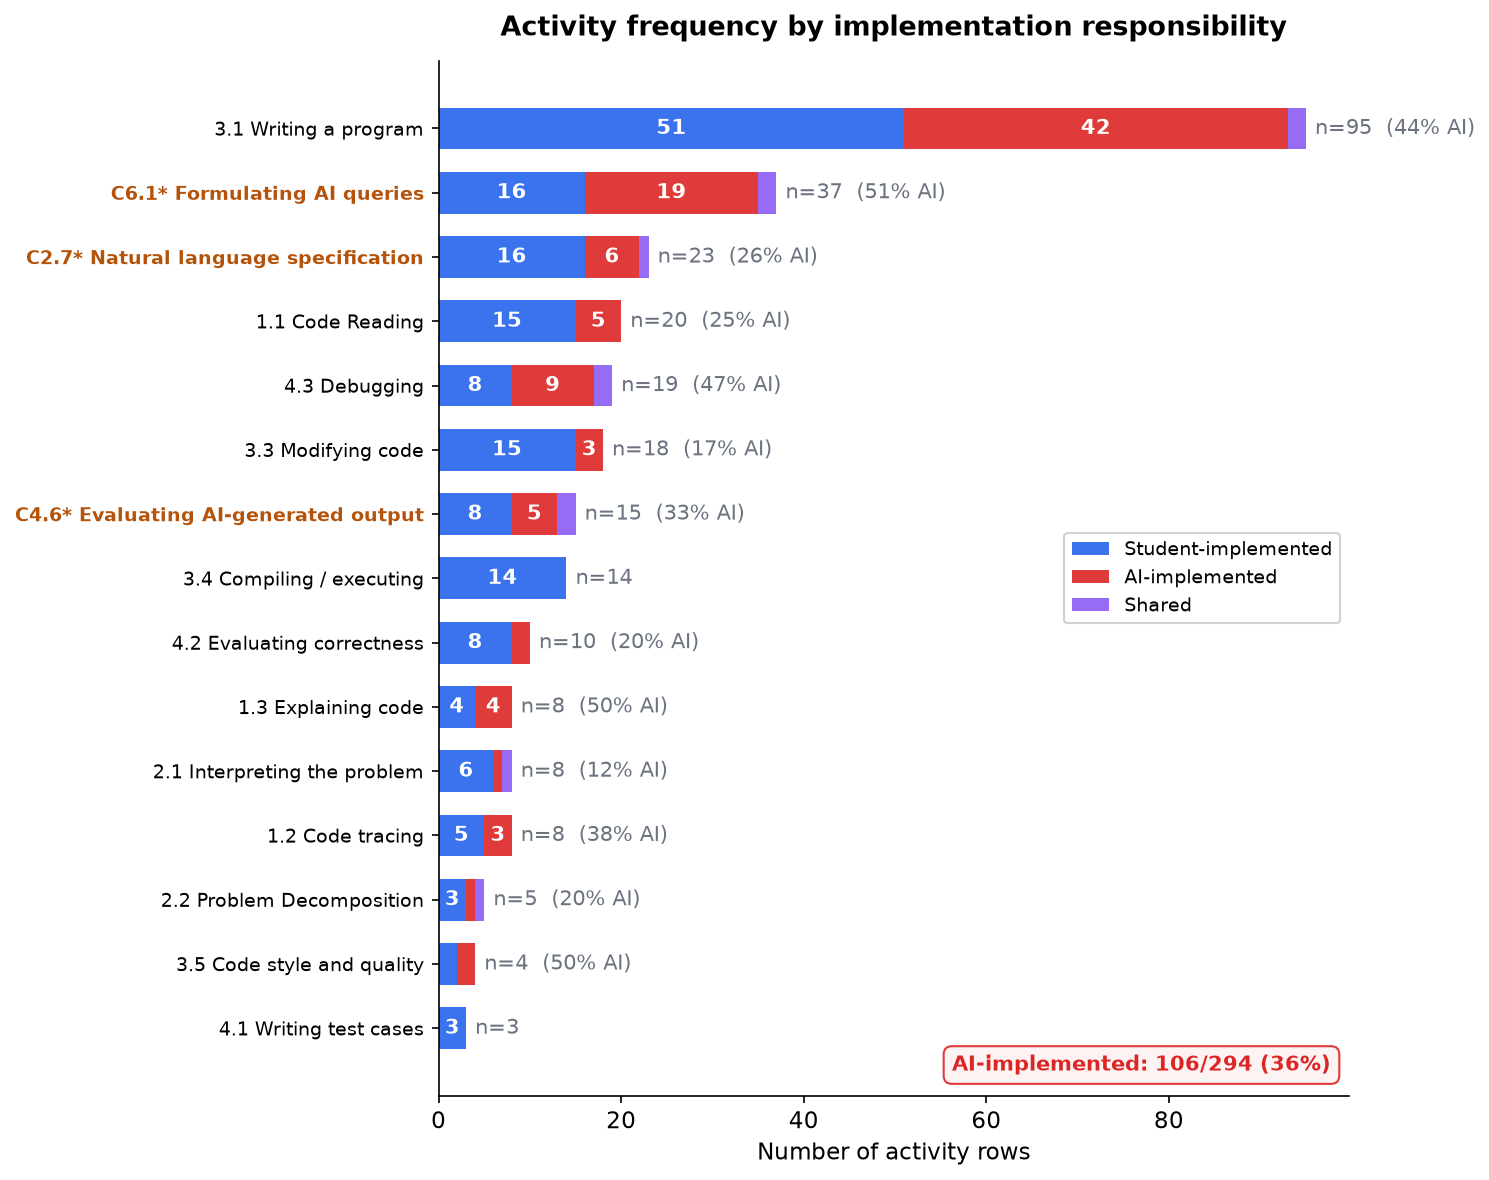

In [ ]:
def fig_implementation_by_activity(df):
    impl_colors = {
        'Student-implemented': '#2563eb',
        'AI-implemented': '#dc2626',
        'Shared': '#8b5cf6',
    }
    impl_order = ['Student-implemented', 'AI-implemented', 'Shared']
 
    df = df.copy()
    df['act_label'] = df['final_code'] + ' ' + df['final_label']
 
    ct = df.groupby(['act_label', 'implementation']).size().unstack(fill_value=0)
    ct = ct.reindex(columns=[c for c in impl_order if c in ct.columns], fill_value=0)
    ct['_total'] = ct.sum(axis=1)
    ct = ct[ct['_total'] >= 3].sort_values('_total', ascending=True)
    totals = ct['_total'].copy()
    ct = ct.drop(columns=['_total'])
 
    # Compute AI% for annotation
    ai_pct = {}
    for act in ct.index:
        ai = ct.loc[act, 'AI-implemented'] if 'AI-implemented' in ct.columns else 0
        ai_pct[act] = int(round(ai / totals[act] * 100))
 
    fig, ax = plt.subplots(figsize=(10, 8))
    left = np.zeros(len(ct))
    for col in ct.columns:
        color = impl_colors.get(col, '#9ca3af')
        ct = ct.rename(index={'NEW-P Prompting / NL specification': 'C2.7* Natural language specification',
                                    'NEW-Q Querying AI for help': 'C6.1* Formulating AI queries',
                                    'NEW-E Evaluating AI output': 'C4.6* Evaluating AI-generated output'})
        
        bars = ax.barh(ct.index, ct[col], left=left, color=color, label=col, height=0.65, alpha=0.9)
        for bar, val in zip(bars, ct[col]):
            if val >= 3:
                ax.text(bar.get_x() + bar.get_width()/2, bar.get_y() + bar.get_height()/2,
                        str(int(val)), ha='center', va='center', fontsize=10, color='white', fontweight='bold')
        left += ct[col].values
 
    for i, (act, total) in enumerate(totals.items()):
        pct = ai_pct[act]
        pct_str = f'n={int(total)}'
        if pct > 0:
            pct_str += f'  ({pct}% AI)'
        ax.text(total + 1, i, pct_str, va='center', fontsize=10, color='#6b7280')
 
    for i, label in enumerate(ct.index):
        if '*' in label:
            ax.get_yticklabels()[i].set_color('#b45309')
            ax.get_yticklabels()[i].set_fontweight('bold')
 
    # Add summary annotation
    total_ai = df[df['implementation'] == 'AI-implemented'].shape[0]
    total_all = len(df)
    ax.text(0.98, 0.02, f'AI-implemented: {total_ai}/{total_all} ({total_ai/total_all*100:.0f}%)',
            transform=ax.transAxes, ha='right', va='bottom', fontsize=10,
            color='#dc2626', fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.4', facecolor='#fef2f2', edgecolor='#dc2626', alpha=0.9))
 
    ax.set_xlabel('Number of activity rows')
    ax.set_title('Activity frequency by implementation responsibility', fontweight='bold', pad=12)
    ax.legend(loc='center right', fontsize=9, framealpha=0.9)
    ax.tick_params(axis='y', labelsize=9)
    plt.tight_layout()
    plt.savefig('fig/fig_impl_by_activity.png', dpi=300, bbox_inches='tight')
    plt.show()
 
fig_implementation_by_activity(df)

### Figure 3B: AI-implemented breakdown: with vs without student evaluation

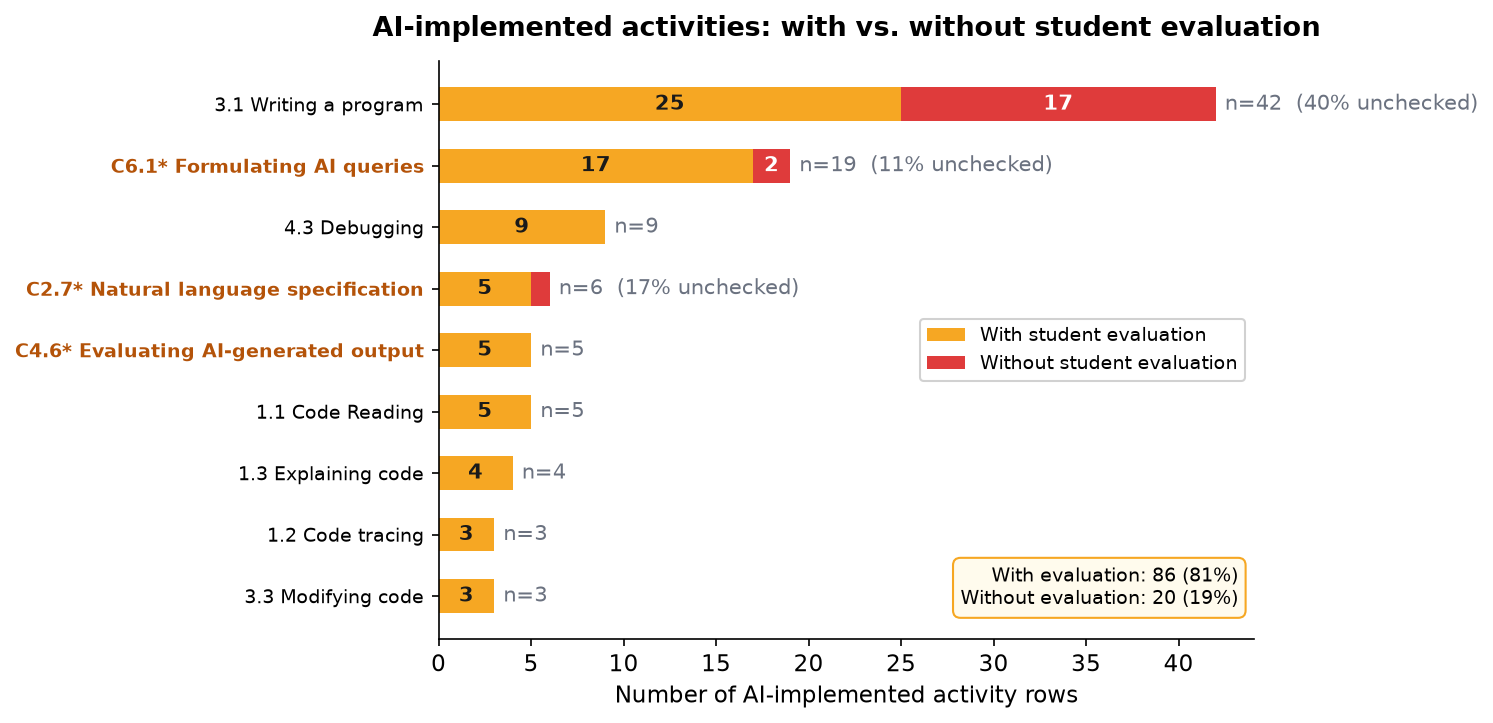

In [ ]:
def fig_ai_subcode(df):
    """Within AI-implemented, show which activities have student evaluation and which don't."""
 
    df_ai = df[df['implementation'] == 'AI-implemented'].copy()
    df_ai['act_label'] = df_ai['final_code'] + ' ' + df_ai['final_label']
 
    sub_colors = {
        'With student evaluation': '#f59e0b',
        'Without student evaluation': '#dc2626',
    }
    sub_order = ['With student evaluation', 'Without student evaluation']
 
    ct = df_ai.groupby(['act_label', 'ai_subcode']).size().unstack(fill_value=0)
    ct = ct.reindex(columns=[c for c in sub_order if c in ct.columns], fill_value=0)
    ct['_total'] = ct.sum(axis=1)
    ct = ct.sort_values('_total', ascending=True)
    # Only include activities with at least 3 AI-implemented rows
    ct = ct[ct['_total'] >= 3]
    totals = ct['_total'].copy()
    ct = ct.drop(columns=['_total'])
 
    # Compute % without evaluation
    no_eval_pct = {}
    for act in ct.index:
        no_eval = ct.loc[act, 'Without student evaluation'] if 'Without student evaluation' in ct.columns else 0
        no_eval_pct[act] = int(round(no_eval / totals[act] * 100))
 
    fig, ax = plt.subplots(figsize=(10, max(4, len(ct) * 0.55)))
    left = np.zeros(len(ct))
    for col in ct.columns:
        color = sub_colors.get(col, '#9ca3af')
        ct = ct.rename(index={'NEW-P Prompting / NL specification': 'C2.7* Natural language specification',
                                    'NEW-Q Querying AI for help': 'C6.1* Formulating AI queries',
                                    'NEW-E Evaluating AI output': 'C4.6* Evaluating AI-generated output'})
        
        bars = ax.barh(ct.index, ct[col], left=left, color=color, label=col, height=0.55, alpha=0.9)
        for bar, val in zip(bars, ct[col]):
            if val >= 2:
                text_color = 'white' if col == 'Without student evaluation' else '#1a1a1a'
                ax.text(bar.get_x() + bar.get_width()/2, bar.get_y() + bar.get_height()/2,
                        str(int(val)), ha='center', va='center', fontsize=10, color=text_color, fontweight='bold')
        left += ct[col].values
 
    for i, (act, total) in enumerate(totals.items()):
        pct = no_eval_pct[act]
        note = f'n={int(total)}'
        if pct > 0 and pct < 100:
            note += f'  ({pct}% unchecked)'
        elif pct == 100:
            note += f'  (all unchecked)'
        ax.text(total + 0.5, i, note, va='center', fontsize=10, color='#6b7280')
 
    for i, label in enumerate(ct.index):
        if '*' in label:
            ax.get_yticklabels()[i].set_color('#b45309')
            ax.get_yticklabels()[i].set_fontweight('bold')
 
    # Summary box
    total_with = df_ai[df_ai['ai_subcode'] == 'With student evaluation'].shape[0]
    total_without = df_ai[df_ai['ai_subcode'] == 'Without student evaluation'].shape[0]
    ax.text(0.98, 0.05,
            f'With evaluation: {total_with} ({total_with/(total_with+total_without)*100:.0f}%)\n'
            f'Without evaluation: {total_without} ({total_without/(total_with+total_without)*100:.0f}%)',
            transform=ax.transAxes, ha='right', va='bottom', fontsize=9,
            bbox=dict(boxstyle='round,pad=0.4', facecolor='#fffbeb', edgecolor='#f59e0b', alpha=0.9))
 
    ax.set_xlabel('Number of AI-implemented activity rows')
    ax.set_title('AI-implemented activities: with vs. without student evaluation',
                 fontweight='bold', pad=12)
    ax.legend(loc='center right', fontsize=9, framealpha=0.9)
    ax.tick_params(axis='y', labelsize=9)
    plt.tight_layout()
    plt.savefig('fig/fig_ai_subcode.png', dpi=300, bbox_inches='tight')
    plt.show()
 
fig_ai_subcode(df)

### RQ3: Do studies measure independent performace?
#### Fig 4: Intended Role x Effect type heatmap

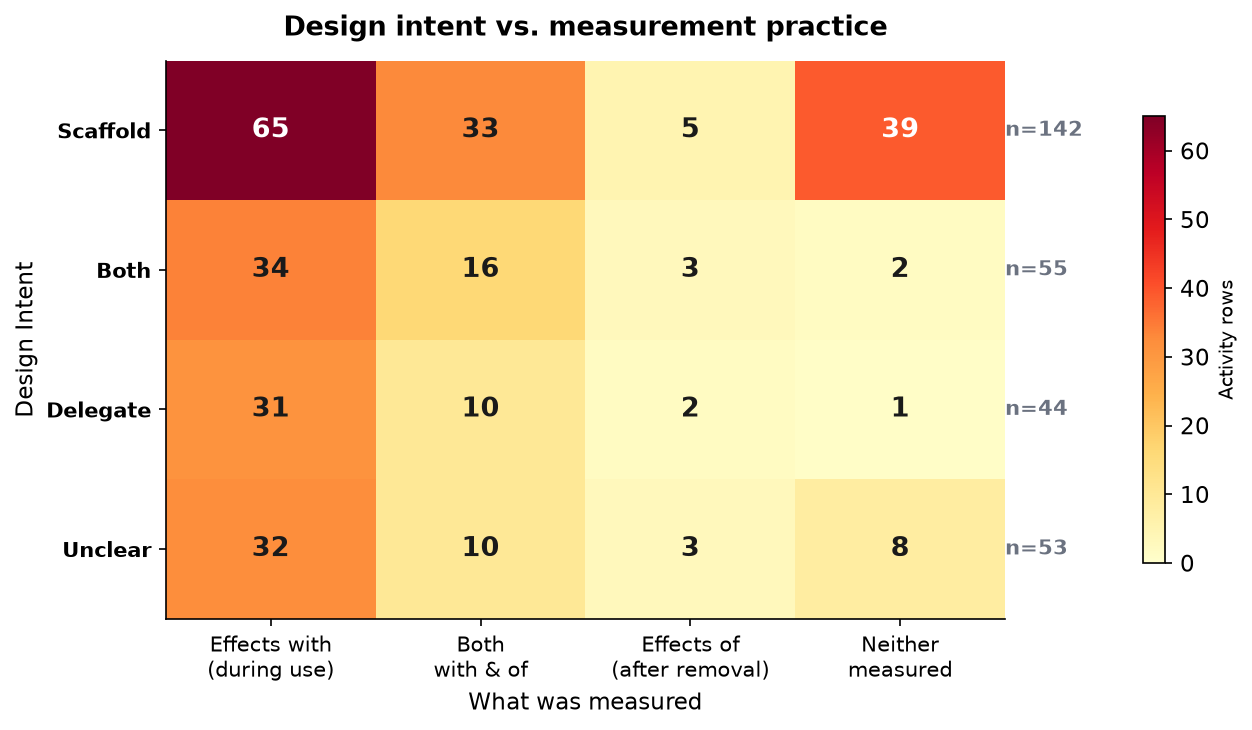

In [23]:
def fig_rq3_role_effect(df):
    """Cross-tab of intended pedagogical role × what was actually measured."""
    df['intended_role'] = df['intended_role'].replace({'scaffold with fading': 'scaffold'})
    roles_order = ['scaffold', 'both', 'delegate', 'unclear']
    eff_order = ['with', 'both', 'of', 'neither']
    eff_labels = ['Effects with\n(during use)', 'Both\nwith & of', 'Effects of\n(after removal)', 'Neither\nmeasured']
    ct = pd.crosstab(df['intended_role'], df['effect_type'])
    ct = ct.reindex(index=[r for r in roles_order if r in ct.index],
                    columns=[c for c in eff_order if c in ct.columns], fill_value=0)
    ct_totals = ct.sum(axis=1)
 
    fig, ax = plt.subplots(figsize=(9, 5))
    vmax = ct.values.max()
    im = ax.imshow(ct.values, cmap='YlOrRd', aspect='auto', vmin=0, vmax=vmax)
 
    for i in range(ct.shape[0]):
        for j in range(ct.shape[1]):
            val = ct.values[i, j]
            text_color = 'white' if val > vmax * 0.55 else '#1a1a1a'
            ax.text(j, i, str(int(val)), ha='center', va='center',
                    fontsize=13, fontweight='bold', color=text_color)
 
    for i, total in enumerate(ct_totals):
        ax.text(ct.shape[1] - 0.5, i, f'n={int(total)}',
                ha='left', va='center', fontsize=10, color='#6b7280', fontweight='bold')
 
    ax.set_xticks(range(len(eff_labels)))
    ax.set_xticklabels(eff_labels, fontsize=10)
    ax.set_yticks(range(len(ct.index)))
    ax.set_yticklabels([r.title() for r in ct.index], fontsize=10, fontweight='bold')
    ax.set_ylabel('Design Intent')
    ax.set_xlabel('What was measured')
    ax.set_title('Design intent vs. measurement practice', fontweight='bold', pad=12)
 
    cbar = plt.colorbar(im, ax=ax, shrink=0.8, pad=0.12)
    cbar.set_label('Activity rows', fontsize=9)
    plt.tight_layout()
    plt.savefig('fig/fig_rq3_role_effect.png', dpi=300, bbox_inches='tight')
    plt.show()
 
fig_rq3_role_effect(df)

#### Figure 5: Unassisted measurement by intended role

##### a

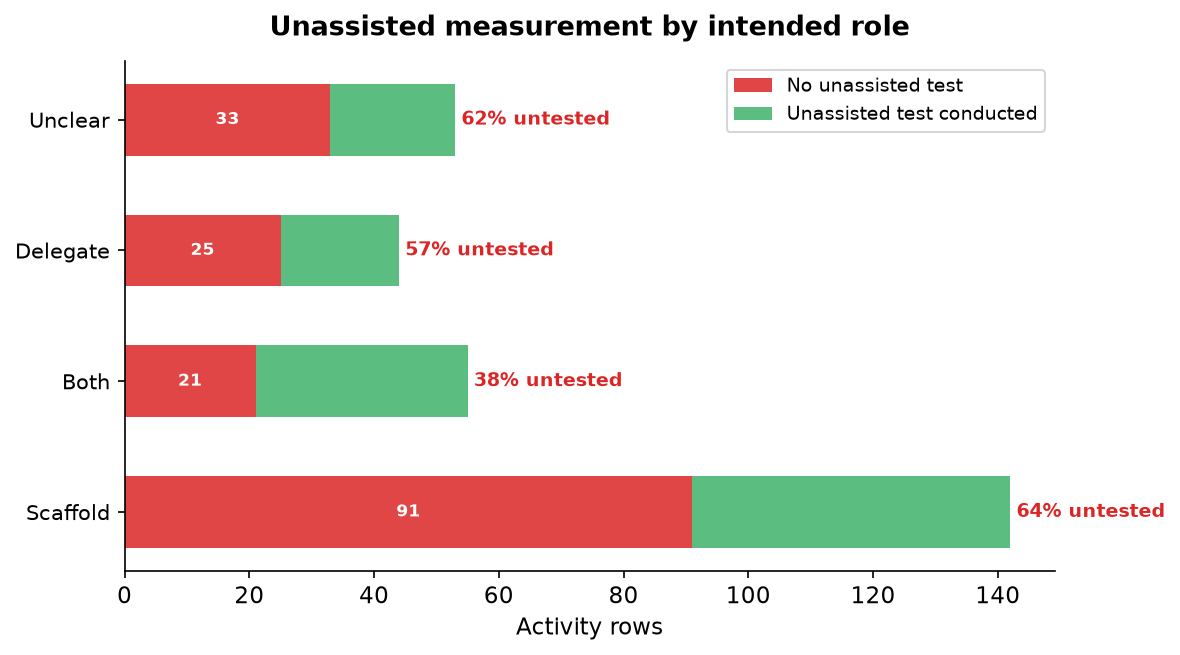

In [24]:
def fig_rq3_unassisted(df):
    """Stacked bar: did the study ever test without the AI tool?"""
    df['intended_role'] = df['intended_role'].replace({'scaffold with fading': 'scaffold'})
    roles_order = ['scaffold', 'both', 'delegate', 'unclear']
 
    ct = pd.crosstab(df['intended_role'], df['unassisted_measurement'])
    ct = ct.reindex(index=[r for r in roles_order if r in ct.index], fill_value=0)
    for col in ['yes', 'no']:
        if col not in ct.columns:
            ct[col] = 0
 
    ct['total'] = ct.sum(axis=1)
    ct['pct_no'] = (ct['no'] / ct['total'] * 100).round(0).astype(int)
 
    fig, ax = plt.subplots(figsize=(8, 4.5))
    y = range(len(ct))
    bars_no = ax.barh(y, ct['no'], color='#dc2626', height=0.55, label='No unassisted test', alpha=0.85)
    bars_yes = ax.barh(y, ct['yes'], left=ct['no'], color='#16a34a', height=0.55,
                       label='Unassisted test conducted', alpha=0.7)
 
    for i, (idx, row) in enumerate(ct.iterrows()):
        ax.text(row['total'] + 1, i, f'{row["pct_no"]}% untested',
                va='center', fontsize=9, color='#dc2626', fontweight='bold')
        if row['no'] >= 3:
            ax.text(row['no']/2, i, str(int(row['no'])),
                    ha='center', va='center', fontsize=8, color='white', fontweight='bold')
 
    ax.set_yticks(y)
    ax.set_yticklabels([r.title() for r in ct.index], fontsize=10)
    ax.set_xlabel('Activity rows')
    ax.set_title('Unassisted measurement by intended role', fontweight='bold', pad=12)
    ax.legend(loc='upper right', fontsize=9)
    plt.tight_layout()
    plt.savefig('fig/fig_rq3_unassisted.png', dpi=300, bbox_inches='tight')
    plt.show()
 
fig_rq3_unassisted(df)

##### b) Measurment gap

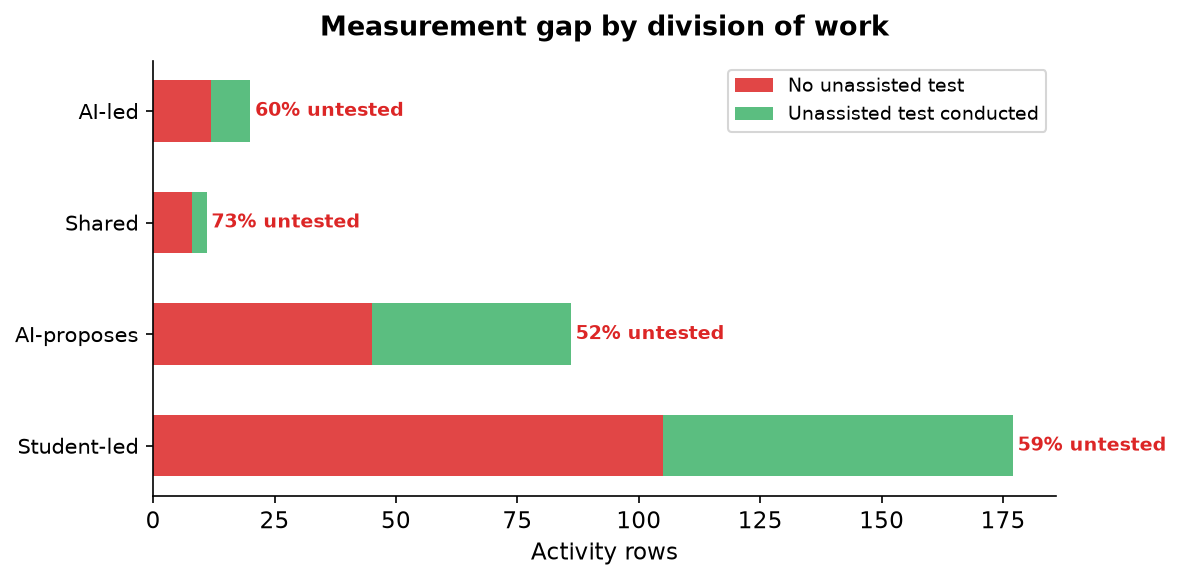

In [26]:
def fig_bonus_measurement_gap(df):
    """Do studies with higher AI delegation also measure less?"""
    div_order = ['student-led', 'AI-proposes student-decides', 'shared / collaborative', 'AI-led']
    div_labels = ['Student-led', 'AI-proposes', 'Shared', 'AI-led']
 
    ct = pd.crosstab(df['division_of_work'], df['unassisted_measurement'])
    ct = ct.reindex(index=[d for d in div_order if d in ct.index], fill_value=0)
    for col in ['yes', 'no']:
        if col not in ct.columns:
            ct[col] = 0
    ct['total'] = ct.sum(axis=1)
    ct['pct_no'] = (ct['no'] / ct['total'] * 100).round(0)
 
    fig, ax = plt.subplots(figsize=(8, 4))
    y = range(len(ct))
    ax.barh(y, ct['no'], color='#dc2626', height=0.55, label='No unassisted test', alpha=0.85)
    ax.barh(y, ct['yes'], left=ct['no'], color='#16a34a', height=0.55,
            label='Unassisted test conducted', alpha=0.7)
 
    for i, (idx, row) in enumerate(ct.iterrows()):
        ax.text(row['total'] + 1, i, f'{int(row["pct_no"])}% untested',
                va='center', fontsize=9, color='#dc2626', fontweight='bold')
 
    ax.set_yticks(y)
    ax.set_yticklabels(div_labels, fontsize=10)
    ax.set_xlabel('Activity rows')
    ax.set_title('Measurement gap by division of work', fontweight='bold', pad=12)
    ax.legend(loc='upper right', fontsize=9)
    plt.tight_layout()
    plt.savefig('fig/fig_rq3_measurement_division.png', dpi=300, bbox_inches='tight')
    plt.show()
 
fig_bonus_measurement_gap(df)
 
